# Duka Electronics — H1 2026 Board Report (storyboard and build)
This notebook plans the one-page board report, builds every chart in code, and documents a chart makeover. Output: `reports/duka_board_report.png` and `.pdf`.

## Storyboard (written before any plotting)
**Audience.** Duka Electronics board members: non-technical, short on time, reading on their phones before next week's meeting.
**Decision.** Where should the company focus its sales effort and budget in H2 2026: which products and branches to protect, which to fix, and what to test?
**Big Idea.** *H1 sales held at KES 71.8M, but growth stalled in Q2 and the business leans on Laptops, Tablets and Nairobi: H2 should protect the core, fix Nakuru and Mombasa, and test phone orders.*

**SCR**
- **Situation:** H1 revenue was KES 71.8M from 1,000 orders across five branches and three channels.
- **Complication:** Q2 revenue was -0.3% on Q1; 85% of revenue comes from just two products; Nakuru and Mombasa, the 2nd and 3rd largest branches, fell about 26% in Q2 (KES 3.9M lost).
- **Resolution:** (1) protect laptop and tablet supply; (2) diagnose Nakuru and Mombasa now; (3) pilot phone orders and Eldoret's momentum before scaling.

| Message (insight title) | Chart | Why this chart |
|---|---|---|
| Q2 was flat on Q1; April peaked | Column chart, 6 months | Time on the x-axis; highlight the peak month |
| Two products bring most revenue | Sorted horizontal bars | Ranking and share; labels stay readable on a phone |
| Two big branches fell in Q2 | Diverging bars (% change) | Shows direction and size of change around zero |
| Phone orders: small, growing, biggest baskets | Horizontal bars (% change) with average order value in the labels | Compares three channels simply |

**Design rules.** One highlight colour (blue) on grey; red only for decline; insight titles; direct labels instead of legends; units on every chart; source line under each chart; text large enough for a phone; the page is tall and narrow so it scrolls rather than zooms.

## Data preparation

In [1]:
import numpy as np, pandas as pd
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display
import os; os.makedirs("figures", exist_ok=True); os.makedirs("reports", exist_ok=True)

d = pd.read_csv("duka_sales.csv", parse_dates=["order_date"])
d["revenue"] = d.quantity * d.unit_price                       # KES
d["month"] = d.order_date.dt.month
d["half"] = np.where(d.month <= 3, "Q1", "Q2")
n, tot = len(d), d.revenue.sum()
mon  = d.groupby("month").revenue.sum()
q    = d.groupby("half").revenue.sum(); q_chg = q.Q2 / q.Q1 - 1
prod = d.groupby("product").revenue.sum().sort_values(ascending=False)
prem = prod.iloc[:2].sum() / tot
br   = d.pivot_table(index="branch", columns="half", values="revenue", aggfunc="sum"); br["chg"] = br.Q2 / br.Q1 - 1
br_n = d.groupby(["branch", "half"]).size()
ch   = d.pivot_table(index="channel", columns="half", values="revenue", aggfunc="sum"); ch["chg"] = ch.Q2 / ch.Q1 - 1
aov  = d.groupby("channel").revenue.sum() / d.groupby("channel").size()
D0, D1 = d.order_date.min(), d.order_date.max()
SOURCE = f"Source: Duka Electronics sales data, {D0:%-d %b}–{D1:%-d %b %Y} ({n:,} orders). Revenue = quantity × unit price."
print(f"Revenue KES {tot/1e6:.1f}M | Q2 vs Q1 {q_chg:+.1%} | top-2 products {prem:.0%} | {D0.date()} to {D1.date()}")

Revenue KES 71.8M | Q2 vs Q1 -0.3% | top-2 products 85% | 2026-01-01 to 2026-06-29


## Chart makeover: before and after
The default chart below is what a quick `df.plot.bar()` gives. The redesigned version applies the design rules from the storyboard.

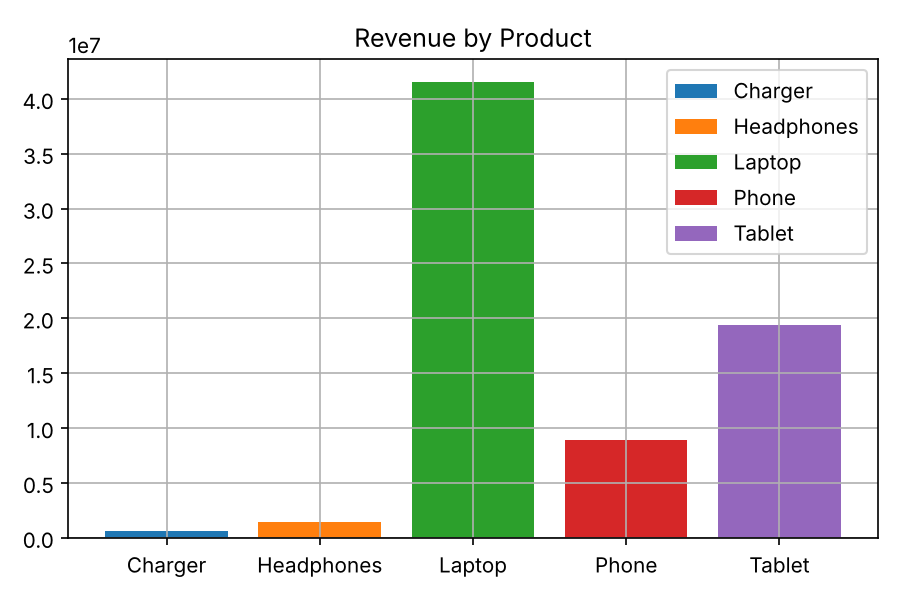

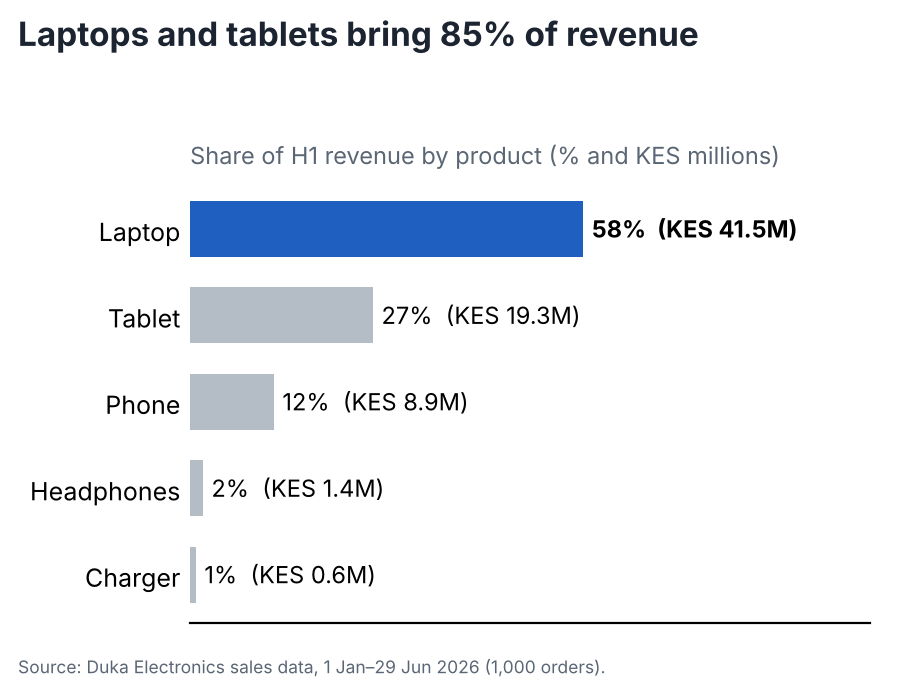

In [2]:
GREY, BLUE, RED, INK, MUTE = "#B4BCC6", "#1F5FBF", "#C8402B", "#1B2430", "#5B6675"
# BEFORE: default styling, generic title, rainbow colours, legend, gridlines, raw KES axis
fig, ax = plt.subplots(figsize=(6, 4))
pr = d.groupby("product").revenue.sum()
ax.bar(pr.index, pr.values, color=plt.cm.tab10.colors[:len(pr)], label=pr.index)
ax.set_title("Revenue by Product"); ax.grid(True); ax.legend()
fig.tight_layout(); fig.savefig("figures/before.png", dpi=150); plt.close(fig)

# AFTER: insight title computed from the data, one highlight colour, sorted, direct labels, units, source
top, second = prod.index[0], prod.index[1]
title = f"{top}s and {second.lower()}s bring {prem:.0%} of revenue"
sh = (prod / tot * 100).sort_values()
with plt.rc_context({"axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False}):
    fig, ax = plt.subplots(figsize=(4.5, 3.4))
    ax.barh(sh.index, sh.values, color=[BLUE if p == top else GREY for p in sh.index], height=0.65)
    for i, (p, v) in enumerate(sh.items()):
        ax.text(v + 1.2, i, f"{v:.0f}%  (KES {prod[p]/1e6:.1f}M)", va="center", fontsize=8.5, weight="bold" if p == top else "normal")
    ax.set_xlim(0, 100); ax.set_xticks([]); ax.tick_params(axis="y", length=0, labelsize=9)
    fig.suptitle(title, x=0.02, ha="left", fontsize=12, weight="bold", color=INK)
    ax.set_title("Share of H1 revenue by product (% and KES millions)", loc="left", fontsize=8.5, color=MUTE)
    fig.text(0.02, 0.01, SOURCE.split(".")[0] + ".", fontsize=6.3, color=MUTE)
    fig.tight_layout(rect=(0, 0.04, 1, 0.94)); fig.savefig("figures/after.png", dpi=200); plt.close(fig)
display(Image("figures/before.png", width=380)); display(Image("figures/after.png", width=380))

### What changed, and why
| # | Design change | Reason |
|---|---|---|
| 1 | Generic title "Revenue by Product" → **insight title** ("Laptops and tablets bring 85% of revenue"), calculated in code | Tells the reader the takeaway before they read the chart, and stays correct if the data changes |
| 2 | Rainbow colours → **one blue highlight on grey** | The eye goes straight to Laptops; colour now carries meaning instead of decoration |
| 3 | Alphabetical vertical columns → **sorted horizontal bars** | Ranking is obvious and category names stay readable on a narrow phone screen |
| 4 | Legend and gridlines → **direct labels** (% and KES millions) | The legend repeated what the x-axis already said; direct labels remove the need to look up values and the confusing `1e7` axis |
| 5 | No units → **units in the subtitle and labels**, plus a **source line** | Readers know what is measured and where it comes from |
| 6 | Small default fonts → **larger text and no chart borders** | Legible at phone width; less clutter around the data |

## Build the one-page report
One tall, narrow figure (4.5 × 18.7 in) so it reads on a phone without zooming. Each chart cell below draws one panel; insight titles are calculated from the data.

In [3]:
W, H = 4.5, 18.7
fig = plt.figure(figsize=(W, H), dpi=240, facecolor="white")
plt.rcParams.update({"font.family": "DejaVu Sans", "axes.spines.top": False, "axes.spines.right": False,
                     "axes.spines.left": False, "axes.edgecolor": GREY})
M = 0.06
fy = lambda inch: 1 - inch / H
def T(x, y_in, s, **k):
    k.setdefault("color", INK); k.setdefault("va", "top"); return fig.text(x, fy(y_in), s, **k)
def rect(x, y_in, w, h_in, color):
    fig.patches.append(plt.Rectangle((x, fy(y_in + h_in)), w, h_in / H, transform=fig.transFigure, color=color, zorder=0))
Y = 0; Yc = 0
def start_section(title, sub, chart_h, lx=0.06, lw=0.88):
    global Y, Yc
    T(M, Y, title, fontsize=11.5, weight="bold", linespacing=1.15)
    T(M, Y + 0.52, sub, fontsize=8, color=MUTE)
    ax = fig.add_axes([lx, fy(Y + 0.80 + chart_h), lw, chart_h / H]); Yc = Y + 0.80 + chart_h
    return ax
def end_section(note=None, pad=0.0):
    global Y
    yy = Yc + 0.12 + pad
    if note: T(M, yy, note, fontsize=8.5, color=MUTE, linespacing=1.3); yy += 0.50
    T(M, yy, "Source: Duka sales data, Jan–Jun 2026", fontsize=6.3, color=MUTE)
    Y = yy + 0.55
print("layout helpers ready")

layout helpers ready


### Header and headline numbers

In [4]:
largest = br[["Q1", "Q2"]].sum(axis=1).idxmax()
T(M, 0.20, "Duka Electronics · H1 2026 board report", fontsize=9.5, color=MUTE, weight="bold")
T(M, 0.50, f"Sales held at KES {tot/1e6:.1f}M, but Q2\nstalled and now rests on {prod.index[0].lower()}s\nand {largest}", fontsize=14, weight="bold", linespacing=1.15)
tiles = [(f"KES {tot/1e6:.1f}M", "revenue, Jan–Jun"), (f"{n:,}", "orders"), (f"{q_chg*100:+.1f}%", "Q2 vs Q1 revenue")]
for i, (big, small) in enumerate(tiles):
    x = M + i * 0.305
    rect(x, 1.50, 0.285, 0.78, "#F2F5F9")
    T(x + 0.012, 1.58, big, fontsize=13, weight="bold", color=BLUE if i != 2 else RED)
    T(x + 0.012, 1.98, small, fontsize=7.5, color=MUTE)
Y = 2.60

### Chart 1 · Monthly revenue (column chart)

In [5]:
peak = mon.idxmax(); pk_name = pd.Timestamp(2026, peak, 1).strftime("%B")
word = "flat on" if abs(q_chg) < 0.01 else ("up on" if q_chg > 0 else "down on")
tail = "then sales eased" if mon.iloc[-1] < mon.max() else "and kept rising"
ax = start_section(f"Q2 was {word} Q1: {pk_name} peaked,\n{tail}", "Monthly revenue, KES millions", 1.15)
names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun"]
cols = [BLUE if m == peak else GREY for m in mon.index]
ax.bar(names, mon.values / 1e6, color=cols, width=0.65)
for i, v in enumerate(mon.values / 1e6): ax.text(i, v + 0.3, f"{v:.1f}", ha="center", fontsize=8.5, weight="bold" if cols[i] == BLUE else "normal")
ax.set_ylim(0, 16); ax.set_yticks([]); ax.tick_params(axis="x", labelsize=8.5, length=0)
end_section(f"Q1 KES {q.Q1/1e6:.1f}M vs Q2 KES {q.Q2/1e6:.1f}M.\nJune is {abs(mon.iloc[-1]/mon.max()-1)*100:.0f}% below {pk_name}.", pad=0.28)

### Chart 2 · Revenue share by product (sorted horizontal bars)

In [6]:
ax = start_section(f"{prod.index[0]}s and {prod.index[1].lower()}s bring {prem:.0%}\nof revenue", "Share of H1 revenue by product, %", 1.45, lx=0.25, lw=0.58)
sh = (prod / tot * 100).sort_values()
ax.barh(sh.index, sh.values, color=[BLUE if p == prod.index[0] else GREY for p in sh.index], height=0.65)
for i, (p, v) in enumerate(sh.items()): ax.text(v + 1, i, f"{v:.0f}%", va="center", fontsize=8.5, weight="bold" if p == prod.index[0] else "normal")
ax.set_xlim(0, 75); ax.set_xticks([]); ax.tick_params(axis="y", labelsize=8.5, length=0)
orders_share = (d["product"] == prod.index[0]).mean()
end_section(f"{prod.index[0]}s are {orders_share:.0%} of orders but {sh[prod.index[0]]:.0f}% of revenue.\nChargers and headphones: {sh[['Charger', 'Headphones']].sum():.0f}% together.")

### Chart 3 · Branch change, Q2 vs Q1 (diverging bars)

In [7]:
bs = br.sort_values("chg"); w1, w2, best = bs.index[0], bs.index[1], bs.index[-1]
avg_drop = abs(bs.chg.iloc[:2].mean()) * 100
ax = start_section(f"{w1} and {w2} fell about {avg_drop:.0f}%\nin Q2; {best} rose {bs.chg.iloc[-1]*100:.0f}%", "Revenue change, Q2 vs Q1, %", 1.65, lx=0.25, lw=0.58)
ax.barh(bs.index, bs.chg * 100, color=[RED if v < 0 else BLUE for v in bs.chg], height=0.65)
for i, (b, r) in enumerate(bs.iterrows()):
    ax.text(r.chg * 100 + (3 if r.chg > 0 else -3), i, f"{r.chg*100:+.0f}%", va="center", ha="left" if r.chg > 0 else "right", fontsize=8.5, weight="bold")
ax.axvline(0, color=INK, lw=0.8); ax.set_xlim(-48, 68); ax.set_xticks([]); ax.tick_params(axis="y", labelsize=8.5, length=0)
lost = (bs.Q2 - bs.Q1).iloc[:2].sum() / 1e6; nsh = br.loc[largest, ["Q1", "Q2"]].sum() / tot * 100
end_section(f"{w1} and {w2} lost KES {abs(lost):.1f}M between quarters.\n{largest}, the largest branch ({nsh:.0f}% of revenue), changed {br.chg[largest]*100:+.0f}%.")

### Chart 4 · Channel change and basket size

In [8]:
chs = ch.sort_values("chg"); fast = chs.index[-1]; big_basket = aov.idxmax()
t4 = f"{fast}s are small but growing,\nwith the biggest baskets" if fast == big_basket else f"{fast}s grew fastest in Q2;\n{big_basket}s have the biggest baskets"
ax = start_section(t4, "Revenue change, Q2 vs Q1, % (average order value, KES thousands)", 1.05, lx=0.30, lw=0.53)
ax.barh([f"{c}\n(KES {aov[c]/1e3:.0f}K)" for c in chs.index], chs.chg * 100, color=[BLUE if v > 0 else GREY for v in chs.chg], height=0.6)
for i, (c, r) in enumerate(chs.iterrows()):
    ax.text(r.chg * 100 + (1.2 if r.chg > 0 else -1.2), i, f"{r.chg*100:+.1f}%", va="center", ha="left" if r.chg > 0 else "right", fontsize=8.5, weight="bold")
ax.axvline(0, color=INK, lw=0.8); ax.set_xlim(-12, 30); ax.set_xticks([]); ax.tick_params(axis="y", labelsize=8, length=0)
end_section()

### Recommendations, caveats and export

content ends at 18.2 of 18.7 inches


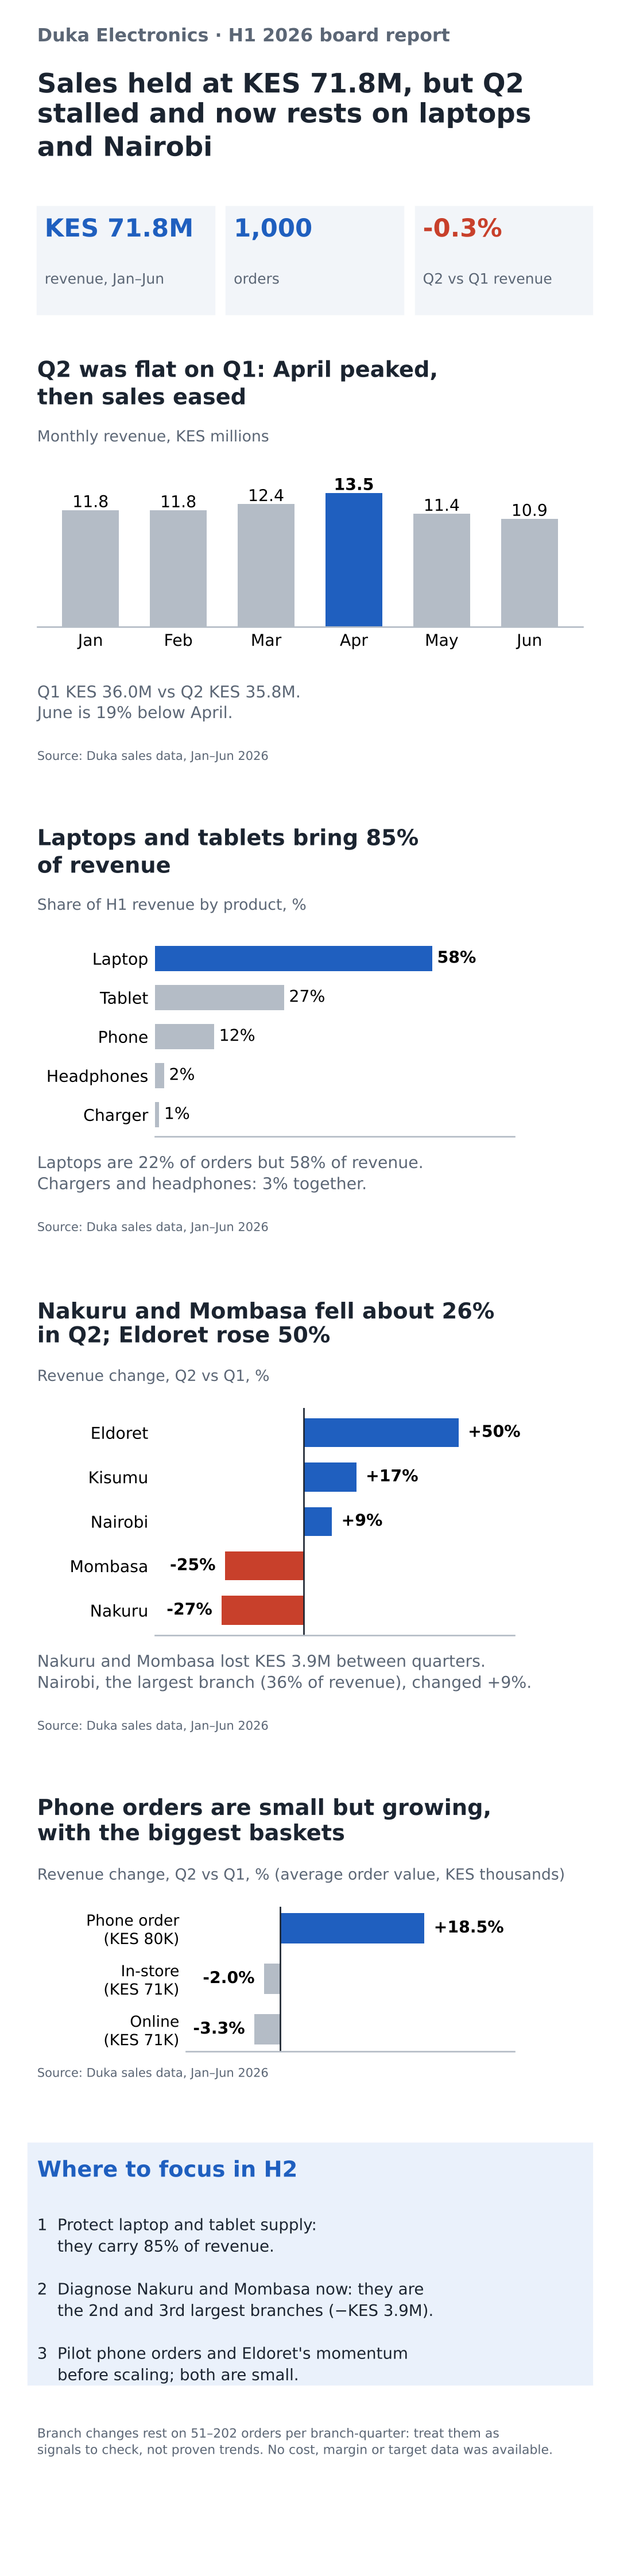

In [9]:
rect(M - 0.015, Y, 0.91, 1.75, "#EAF1FB")
T(M, Y + 0.12, "Where to focus in H2", fontsize=11.5, weight="bold", color=BLUE)
recs = [f"1  Protect {prod.index[0].lower()} and {prod.index[1].lower()} supply:\n    they carry {prem:.0%} of revenue.",
        f"2  Diagnose {w1} and {w2} now: they are\n    the 2nd and 3rd largest branches (−KES {abs(lost):.1f}M).",
        f"3  Pilot {fast.lower()}s and {best}'s momentum\n    before scaling; both are small."]
T(M, Y + 0.52, "\n\n".join(recs), fontsize=8.3, linespacing=1.35)
nmin, nmax = int(br_n.min()), int(br_n.max())
T(M, Y + 2.05, f"Branch changes rest on {nmin}–{nmax} orders per branch-quarter: treat them as\nsignals to check, not proven trends. No cost, margin or target data was available.", fontsize=6.6, color=MUTE, linespacing=1.3)
print("content ends at", round(Y + 2.6, 1), "of", H, "inches")
fig.savefig("reports/duka_board_report.png", dpi=240); fig.savefig("reports/duka_board_report.pdf")
display(Image("reports/duka_board_report.png", width=380))